In [28]:
import pandas as pd
import numpy as np

In [29]:
df=pd.read_csv('data/cleaned_spam.csv')

In [30]:
df.head()

,label,msg
0,ham,go jurong point crazy available bugis n great ...
1,ham,ok lar joking wif u oni
2,spam,free entry wkly comp win fa cup final tkts st ...
3,ham,u dun say early hor u c already say
4,ham,nah dont think goes usf lives around though


In [31]:
import pandas as pd

train_df = pd.read_csv('data/train.csv')
test_df = pd.read_csv('data/test.csv')

x_train, y_train = train_df['msg'], train_df['label']
x_test, y_test = test_df['msg'], test_df['label']

In [32]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

pipeline = Pipeline([
    ('tfidf', TfidfVectorizer()),
    ('model', LogisticRegression(max_iter=1000))
])

pipeline.fit(x_train, y_train)
y_pred = pipeline.predict(x_test)

In [33]:
from sklearn.metrics import (accuracy_score,classification_report,confusion_matrix)

accuracy=accuracy_score(y_test, y_pred)
report=classification_report(y_test, y_pred)
matrix=confusion_matrix(y_test, y_pred)

print(f'Accuracy: {accuracy}')
print(f'Classification Report:\n{report}')
print(f'Confusion Matrix:\n{matrix}')

Accuracy: 0.9564375605033882
Classification Report:
              precision    recall  f1-score   support

         ham       0.95      1.00      0.98       902
        spam       0.98      0.67      0.80       131

    accuracy                           0.96      1033
   macro avg       0.97      0.83      0.89      1033
weighted avg       0.96      0.96      0.95      1033

Confusion Matrix:
[[900   2]
 [ 43  88]]


In [21]:
balanced_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer()),
    ('model', LogisticRegression(max_iter=1000, class_weight='balanced'))
])

balanced_pipeline.fit(x_train, y_train)
balanced_y_pred = balanced_pipeline.predict(x_test)

In [22]:
accuracy_balanced=accuracy_score(y_test, balanced_y_pred)
report_balanced=classification_report(y_test, balanced_y_pred)
matrix_balanced=confusion_matrix(y_test, balanced_y_pred)

print(f'Balanced Accuracy: {accuracy_balanced}')
print(f'Balanced Classification Report:\n{report_balanced}')
print(f'Balanced Confusion Matrix:\n{matrix_balanced}')

Balanced Accuracy: 0.9690222652468539
Balanced Classification Report:
              precision    recall  f1-score   support

         ham       0.99      0.98      0.98       902
        spam       0.86      0.91      0.88       131

    accuracy                           0.97      1033
   macro avg       0.92      0.94      0.93      1033
weighted avg       0.97      0.97      0.97      1033

Balanced Confusion Matrix:
[[882  20]
 [ 12 119]]


In [23]:
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import cross_val_score

scores = cross_val_score(
    balanced_pipeline,
    x_train,
    y_train,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring='f1_macro'
)

print(f'Cross-validated F1 scores: {scores}')
print(f'Mean F1 score: {scores.mean():.3f} (+/- {scores.std() * 2:.3f})')

Cross-validated F1 scores: [0.92604683 0.93152888 0.92907998 0.93262797 0.95168523]
Mean F1 score: 0.934 (+/- 0.018)


In [24]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'model__C': [0.1, 0.5, 1, 5, 10],
    'model__class_weight': ['balanced', None]
}

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring='f1_macro',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(x_train, y_train)
print("Best Parameters:", grid_search.best_params_)
print("Best CV Score:", grid_search.best_score_)

Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best Parameters: {'model__C': 10, 'model__class_weight': 'balanced'}
Best CV Score: 0.9429435794451848


In [25]:
best_model = grid_search.best_estimator_
y_pred_final = best_model.predict(x_test)

print("Final Accuracy:",accuracy_score(y_test, y_pred_final))
print(classification_report(y_test, y_pred_final))
print(confusion_matrix(y_test, y_pred_final))

Final Accuracy: 0.9806389157792836
              precision    recall  f1-score   support

         ham       0.99      0.99      0.99       902
        spam       0.91      0.94      0.92       131

    accuracy                           0.98      1033
   macro avg       0.95      0.96      0.96      1033
weighted avg       0.98      0.98      0.98      1033

[[890  12]
 [  8 123]]


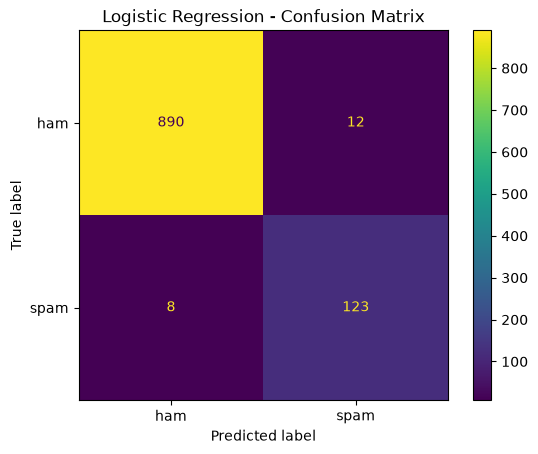

In [26]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(y_test,y_pred_final)

plt.title("Logistic Regression - Confusion Matrix")

plt.show()

In [27]:
import joblib
joblib.dump(best_model, '../models/logistic_regression_text.pkl')

['../models/logistic_regression_text.pkl']